# Conditional Flow Matching for Synthetic Liver Blood-Test Data

**Research question:** Can conditional flow matching learn realistic joint distributions of liver-related blood-test results for patients with and without a liver-disease label, and how do model capacity and sampling steps affect sample quality?

**Source:** UCI Indian Liver Patient Dataset (ILPD), dataset ID 225; 583 records with lab measurements and binary labels. [Official dataset / citation](https://archive.ics.uci.edu/dataset/225/ilpd) (Ramana & Venkateswarlu, UCI, DOI: 10.24432/C5D02C).

**Scope:** This is a **generative modeling exercise**, *not* a liver-disease detector, diagnosis tool, or clinically validated synthetic dataset. Dataset labels and sampling biases limit generalizability. Never use generated records for patient care.

**Notebook plan:** (1) visualize a two-moons toy example; (2) prepare eight continuous liver lab features; (3) fit conditional flow matching; (4) compare architecture choices and a Gaussian baseline; (5) vary ODE sampling steps; (6) evaluate held-out data and save report figures/tables.

> Flow matching trains using straight-line conditional interpolation between noise and data. The learned ODE trajectories **need not be straight**.

## 0. Reproducibility and imports

Select the `liver-flow-matching` Conda environment as the VS Code Jupyter kernel. Edit the configuration variables in the next cell to change training settings. No `.env` file is needed.

In [1]:
from pathlib import Path
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import rbf_kernel
from scipy.stats import wasserstein_distance
from ucimlrepo import fetch_ucirepo

SEED = 42
EPOCHS = 250
TOY_EPOCHS = 300
BATCH_SIZE = 64
LEARNING_RATE = 0.001
N_SAMPLES_PER_CLASS = 400
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cpu')

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    # if torch.cuda.is_available():
    #     torch.cuda.manual_seed_all(seed)
reset_seed()
plt.rcParams.update({'figure.figsize': (8, 5), 'figure.dpi': 110})
print('Device:', DEVICE, '| Epochs:', EPOCHS, '| Output:', OUTPUT_DIR.resolve())

Device: cpu | Epochs: 250 | Output: C:\Users\angel\CS6956-FlowMatching\outputs


## 1. Flow matching: a 2D intuition

For a noise point $z\sim\mathcal N(0,I)$ and observed point $x$, define $x_t=(1-t)z+tx$. The target conditional velocity is $u=x-z$. A neural network $v_\theta(x_t,t,c)$ is trained with mean squared error to approximate $u$; $c$ is an optional condition. We then integrate $dx/dt=v_\theta(x,t,c)$ from $t=0$ to $t=1$ using Euler steps.

In [2]:
class VelocityMLP(nn.Module):
    def __init__(self, feature_dim, hidden_dim=64, depth=2, num_conditions=2):
        super().__init__()
        layers = []
        input_dim = feature_dim + 1 + num_conditions
        for layer_index in range(depth):
            layers += [nn.Linear(input_dim if layer_index == 0 else hidden_dim, hidden_dim), nn.SiLU()]
        layers.append(nn.Linear(hidden_dim, feature_dim))
        self.network = nn.Sequential(*layers)
        self.num_conditions = num_conditions

    def forward(self, input_features, time_values, class_labels):
        condition_vectors = torch.nn.functional.one_hot(class_labels.long(), self.num_conditions).float()
        inputs = torch.cat([input_features, time_values, condition_vectors], dim=1)
        return self.network(inputs)


def train_flow(data_features, data_labels, hidden_dim=64, depth=2, epochs=250, seed=42,
               batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE):
    reset_seed(seed)
    feature_tensor = torch.tensor(data_features, dtype=torch.float32)
    label_tensor = torch.tensor(data_labels, dtype=torch.long)
    dataset = TensorDataset(feature_tensor, label_tensor)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    model = VelocityMLP(feature_tensor.shape[1], hidden_dim, depth).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    losses = []
    for epoch in range(epochs):
        model.train()
        batch_losses = []
        for real_features, class_labels in loader:
            real_features, class_labels = real_features.to(DEVICE), class_labels.to(DEVICE)
            noise_features = torch.randn_like(real_features)
            time_values = torch.rand((real_features.shape[0], 1), device=DEVICE)
            intermediate_features = (1 - time_values) * noise_features + time_values * real_features
            target_velocity = real_features - noise_features
            predicted_velocity = model(intermediate_features, time_values, class_labels)
            loss = torch.mean((predicted_velocity - target_velocity) ** 2)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        losses.append(float(np.mean(batch_losses)))
    return model, losses


@torch.no_grad()
def sample_flow(model, class_labels, steps=30, seed=42, initial_noise=None):
    model.eval()
    class_labels = np.asarray(class_labels, dtype=np.int64)
    labels_tensor = torch.tensor(class_labels, dtype=torch.long, device=DEVICE)
    if initial_noise is None:
        local_generator = torch.Generator(device='cpu').manual_seed(seed)
        features = torch.randn((len(class_labels), model.network[-1].out_features), generator=local_generator).to(DEVICE)
    else:
        features = torch.as_tensor(initial_noise, dtype=torch.float32, device=DEVICE).clone()
    for step_index in range(steps):
        current_time = torch.full((len(class_labels), 1), step_index / steps, device=DEVICE)
        predicted_velocity = model(features, current_time, labels_tensor)
        features = features + predicted_velocity / steps
    return features.cpu().numpy()

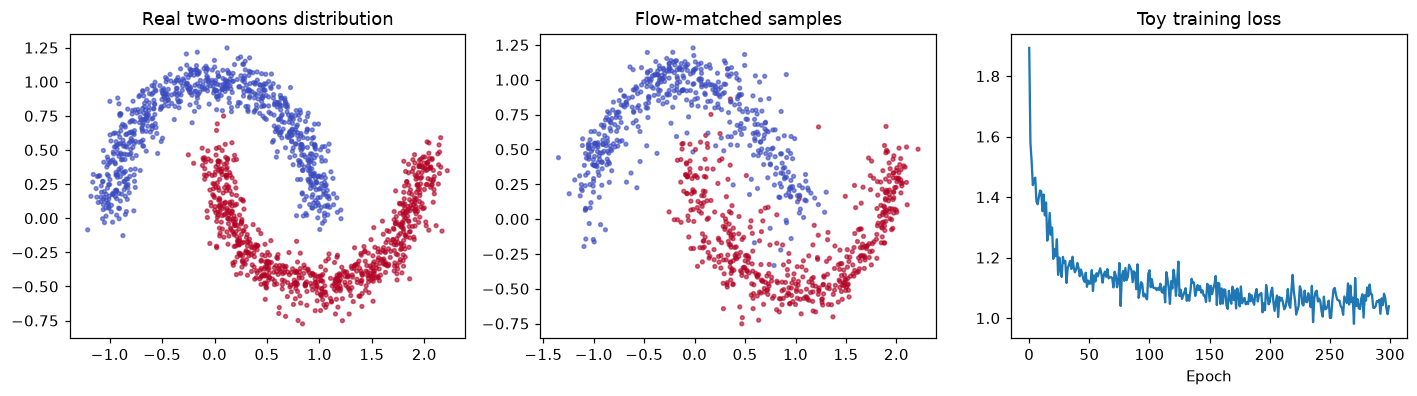

In [3]:
toy_features, toy_labels = make_moons(n_samples=1500, noise=0.09, random_state=SEED)
toy_scaler = StandardScaler()
toy_features_scaled = toy_scaler.fit_transform(toy_features).astype('float32')
toy_model, toy_losses = train_flow(toy_features_scaled, toy_labels, hidden_dim=64, depth=2,
                                   epochs=TOY_EPOCHS, seed=SEED)
toy_generated = sample_flow(toy_model, np.tile([0, 1], 500), steps=40, seed=SEED)
toy_generated = toy_scaler.inverse_transform(toy_generated)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
axes[0].scatter(toy_features[:, 0], toy_features[:, 1], c=toy_labels, s=6, alpha=0.6, cmap='coolwarm')
axes[0].set_title('Real two-moons distribution')
axes[1].scatter(toy_generated[:, 0], toy_generated[:, 1], c=np.tile([0, 1], 500), s=6, alpha=0.6, cmap='coolwarm')
axes[1].set_title('Flow-matched samples')
axes[2].plot(toy_losses)
axes[2].set_title('Toy training loss'); axes[2].set_xlabel('Epoch')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / '01_toy_flow_matching.png', bbox_inches='tight')
plt.show()

## 2. Real liver data, preprocessing, and leakage prevention

The UCI dataset has 583 records and 10 covariates (including age and gender). We model **eight continuous blood-test values** only, conditioned on the class label; this avoids treating categorical gender and integer age as continuous outputs. `Selector=1` indicates liver patient and `Selector=2` indicates non-liver patient according to the UCI listing.

We split by label **before** fitting imputers, log transforms, or scaling. Continuous skewed lab measurements are `log1p` transformed after nonnegative clipping of training/validation inputs (a defensive choice, not a clinical rule), and then standardized using training-set statistics only. Log-inverse of generated values may yield negative raw measurements: we measure this as an invalidity rather than silently clipping generated results.

In [4]:
dataset = fetch_ucirepo(id=225)
raw_features = dataset.data.features.copy()
raw_targets = dataset.data.targets.copy()
print('Original columns:', list(raw_features.columns))
print('Target columns:', list(raw_targets.columns))
display(raw_features.head())

FEATURE_COLUMNS = ['TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'A/G Ratio']
missing_columns = sorted(set(FEATURE_COLUMNS) - set(raw_features.columns))
if missing_columns:
    raise ValueError(f'Unexpected UCI columns: {missing_columns}. Inspect the printed column list.')

features_all = raw_features[FEATURE_COLUMNS].apply(pd.to_numeric, errors='coerce')
target_column = 'Selector' if 'Selector' in raw_targets.columns else raw_targets.columns[0]
original_labels = pd.to_numeric(raw_targets[target_column], errors='coerce')
valid_target = original_labels.isin([1, 2])
features_all = features_all.loc[valid_target].reset_index(drop=True)
labels_all = (original_labels.loc[valid_target].to_numpy() == 1).astype('int64')
# 1 = liver patient, 0 = non-liver patient
train_indices, test_indices = train_test_split(np.arange(len(features_all)), test_size=0.25,
                                               random_state=SEED, stratify=labels_all)
train_raw = features_all.iloc[train_indices].copy()
test_raw = features_all.iloc[test_indices].copy()
train_labels, test_labels = labels_all[train_indices], labels_all[test_indices]

train_medians = train_raw.median(numeric_only=True)
train_imputed = train_raw.fillna(train_medians).clip(lower=0)
test_imputed = test_raw.fillna(train_medians).clip(lower=0)
train_log = np.log1p(train_imputed)
test_log = np.log1p(test_imputed)
lab_scaler = StandardScaler()
train_scaled = lab_scaler.fit_transform(train_log).astype('float32')
test_scaled = lab_scaler.transform(test_log).astype('float32')

print('Total:', len(features_all), '| Train:', len(train_scaled), '| Held-out test:', len(test_scaled))
print('Label counts (1=liver patient):', pd.Series(labels_all).value_counts().sort_index().to_dict())
print('Missing values before imputation:', train_raw.isna().sum().to_dict())

def inverse_lab_transform(standardized_features):
    return np.expm1(lab_scaler.inverse_transform(standardized_features))

def as_lab_frame(raw_values):
    return pd.DataFrame(raw_values, columns=FEATURE_COLUMNS)

Original columns: ['Age', 'Gender', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'A/G Ratio']
Target columns: ['Selector']


,Age,Gender,TB,DB,Alkphos,Sgpt,Sgot,TP,ALB,A/G Ratio
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40


Total: 583 | Train: 437 | Held-out test: 146
Label counts (1=liver patient): {0: 167, 1: 416}
Missing values before imputation: {'TB': 0, 'DB': 0, 'Alkphos': 0, 'Sgpt': 0, 'Sgot': 0, 'TP': 0, 'ALB': 0, 'A/G Ratio': 4}


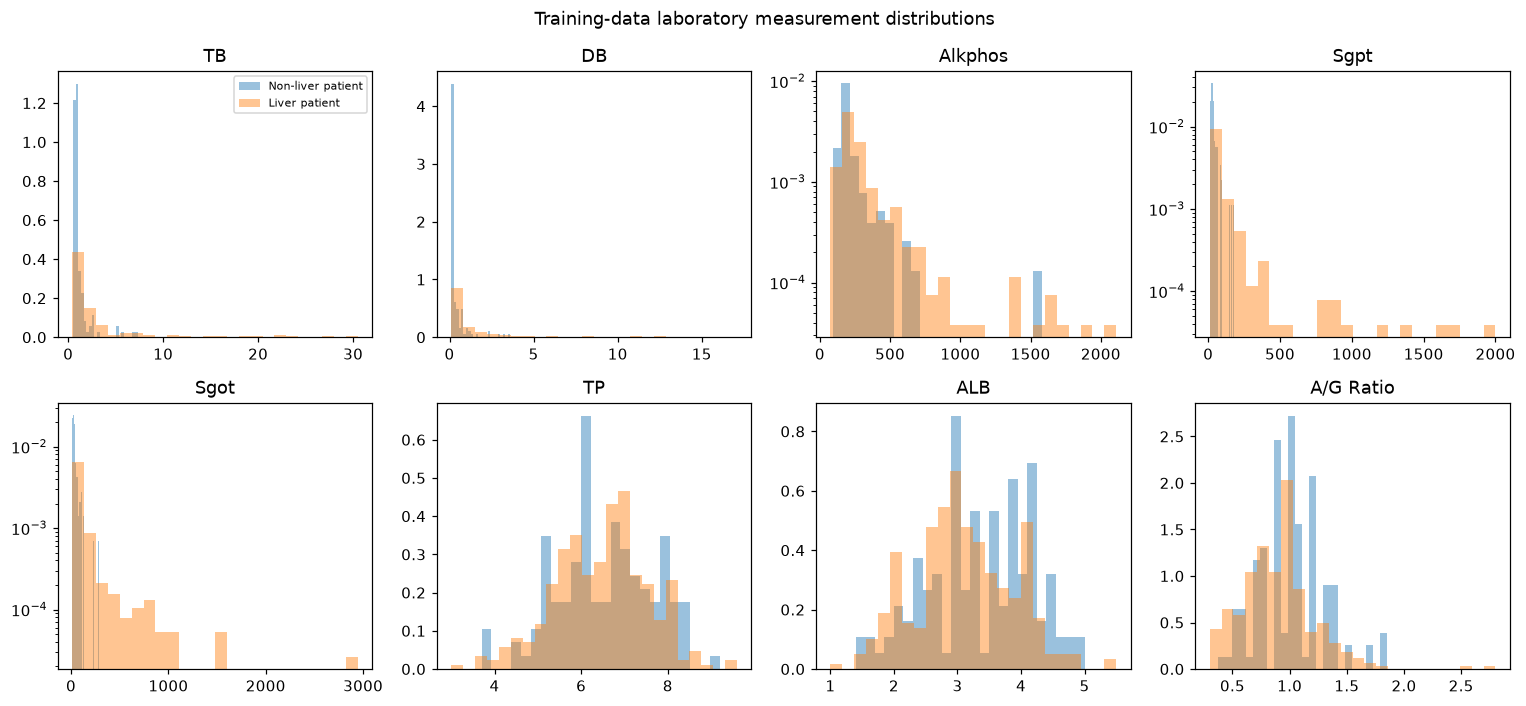

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for axis, feature_name in zip(axes.flat, FEATURE_COLUMNS):
    for diagnosis_label, group_name in [(0, 'Non-liver patient'), (1, 'Liver patient')]:
        values = train_imputed.loc[train_labels == diagnosis_label, feature_name]
        axis.hist(values, bins=24, alpha=0.45, density=True, label=group_name)
    axis.set_title(feature_name)
    axis.set_yscale('log') if feature_name in ['Alkphos', 'Sgpt', 'Sgot'] else None
axes[0, 0].legend(fontsize=7)
fig.suptitle('Training-data laboratory measurement distributions')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / '02_real_lab_distributions.png', bbox_inches='tight')
plt.show()

## 3. Model architecture experiments

Compare smaller, medium, and deeper MLPs while keeping the optimizer, training epochs, preprocessing, and dataset split fixed. These experiments measure *generative fidelity*, not classification accuracy.

Training: small_32x2
Training: medium_64x2
Training: deep_64x4


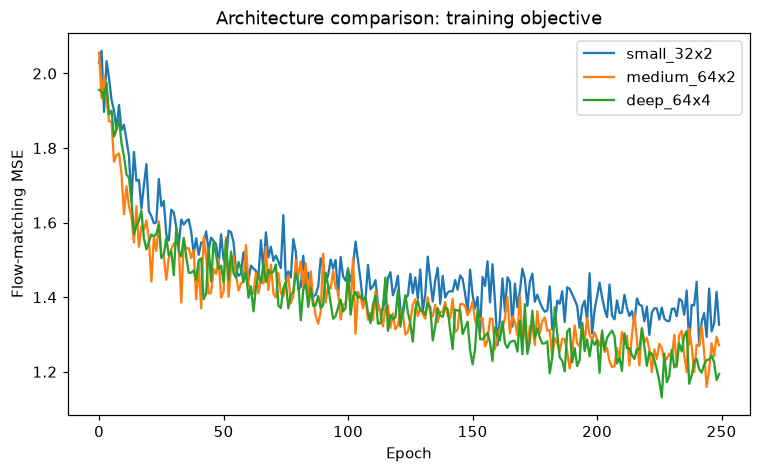

In [6]:
MODEL_CONFIGURATIONS = [
    {'name': 'small_32x2', 'hidden_dim': 32, 'depth': 2},
    {'name': 'medium_64x2', 'hidden_dim': 64, 'depth': 2},
    {'name': 'deep_64x4', 'hidden_dim': 64, 'depth': 4},
]
trained_models = {}
training_history = {}
for configuration in MODEL_CONFIGURATIONS:
    print('Training:', configuration['name'])
    trained_model, model_losses = train_flow(train_scaled, train_labels,
        hidden_dim=configuration['hidden_dim'], depth=configuration['depth'], epochs=EPOCHS, seed=SEED)
    trained_models[configuration['name']] = trained_model
    training_history[configuration['name']] = model_losses

fig, axis = plt.subplots(figsize=(8, 4.5))
for name, losses in training_history.items():
    axis.plot(losses, label=name)
axis.set(xlabel='Epoch', ylabel='Flow-matching MSE', title='Architecture comparison: training objective')
axis.legend()
fig.savefig(OUTPUT_DIR / '03_architecture_training_losses.png', bbox_inches='tight')
plt.show()

## 4. Quantitative generative evaluation

**Evaluation is on held-out patients, split by label.** All data-space fidelity metrics are computed in the same **training-standardized log-lab feature space** to prevent large-magnitude enzymes from dominating.

- **Marginal Wasserstein (lower better):** Mean over eight 1D distances between generated and held-out distributions.
- **RBF MMD² (lower better):** Multivariate distribution discrepancy using a fixed Gaussian kernel bandwidth, estimated on independent sample sets. It may be negative due to finite-sample estimation if an unbiased formula is used; here we use a nonnegative *biased* estimate.
- **Correlation MAE (lower better):** Mean absolute difference between off-diagonal feature correlations.
- **Validity (higher better):** Fraction of generated records with nonnegative lab values and with direct bilirubin ≤ total bilirubin, albumin ≤ total protein.

These metrics are noisy because the holdout is small; differences should not be over-interpreted. Conditional Gaussian baseline is fitted using **training patients only**.

In [7]:
def rbf_mmd_squared(first_samples, second_samples, gamma=1/8):
    first_kernel = rbf_kernel(first_samples, first_samples, gamma=gamma)
    second_kernel = rbf_kernel(second_samples, second_samples, gamma=gamma)
    cross_kernel = rbf_kernel(first_samples, second_samples, gamma=gamma)
    return float(first_kernel.mean() + second_kernel.mean() - 2 * cross_kernel.mean())


def evaluate_one_group(generated_scaled, heldout_scaled):
    marginal_wasserstein = np.mean([
        wasserstein_distance(generated_scaled[:, feature_index], heldout_scaled[:, feature_index])
        for feature_index in range(generated_scaled.shape[1])
    ])
    generated_corr = np.nan_to_num(np.corrcoef(generated_scaled, rowvar=False))
    heldout_corr = np.nan_to_num(np.corrcoef(heldout_scaled, rowvar=False))
    off_diagonal = ~np.eye(generated_scaled.shape[1], dtype=bool)
    correlation_error = np.mean(np.abs(generated_corr[off_diagonal] - heldout_corr[off_diagonal]))
    generated_original_units = inverse_lab_transform(generated_scaled)
    bilirubin_condition = generated_original_units[:, 1] <= generated_original_units[:, 0]
    albumin_condition = generated_original_units[:, 6] <= generated_original_units[:, 5]
    positivity_condition = (generated_original_units >= 0).all(axis=1)
    validity_fraction = np.mean(bilirubin_condition & albumin_condition & positivity_condition)
    return {'wasserstein': marginal_wasserstein,
            'mmd2': rbf_mmd_squared(generated_scaled, heldout_scaled),
            'correlation_mae': correlation_error,
            'valid_fraction': validity_fraction}


def evaluate_conditional_generator(generator_fn, n_per_class=N_SAMPLES_PER_CLASS):
    results = []
    for diagnosis_label in [0, 1]:
        label_array = np.full(n_per_class, diagnosis_label, dtype='int64')
        generated_scaled = generator_fn(label_array)
        heldout_scaled = test_scaled[test_labels == diagnosis_label]
        metrics = evaluate_one_group(generated_scaled, heldout_scaled)
        results.append({'group': 'Liver patient' if diagnosis_label else 'Non-liver patient', **metrics})
    return pd.DataFrame(results)


def sample_gaussian_baseline(class_labels, seed=SEED):
    generator = np.random.default_rng(seed)
    results = np.empty((len(class_labels), train_scaled.shape[1]), dtype='float32')
    for diagnosis_label in [0, 1]:
        selected = np.flatnonzero(class_labels == diagnosis_label)
        training_subset = train_scaled[train_labels == diagnosis_label]
        mean_vector = training_subset.mean(axis=0)
        covariance_matrix = np.cov(training_subset, rowvar=False) + np.eye(train_scaled.shape[1]) * 1e-3
        results[selected] = generator.multivariate_normal(mean_vector, covariance_matrix, size=len(selected))
    return results

metric_tables = []
for model_name, trained_model in trained_models.items():
    group_metrics = evaluate_conditional_generator(
        lambda labels, model=trained_model: sample_flow(model, labels, steps=40, seed=SEED))
    group_metrics.insert(0, 'model', model_name)
    metric_tables.append(group_metrics)
baseline_metrics = evaluate_conditional_generator(sample_gaussian_baseline)
baseline_metrics.insert(0, 'model', 'conditional_gaussian_baseline')
metric_tables.append(baseline_metrics)
architecture_metrics = pd.concat(metric_tables, ignore_index=True)
display(architecture_metrics.round(4))
architecture_metrics.to_csv(OUTPUT_DIR / 'architecture_metrics_by_group.csv', index=False)

architecture_summary = architecture_metrics.groupby('model', as_index=False)[
    ['wasserstein', 'mmd2', 'correlation_mae', 'valid_fraction']].mean()
display(architecture_summary.round(4))
architecture_summary.to_csv(OUTPUT_DIR / 'architecture_metrics_summary.csv', index=False)

,model,group,wasserstein,mmd2,correlation_mae,valid_fraction
0,small_32x2,Non-liver patient,0.2477,0.0339,0.1807,0.9200
1,small_32x2,Liver patient,0.2620,0.0255,0.1116,0.9350
2,medium_64x2,Non-liver patient,0.2028,0.0273,0.1620,0.9525
3,medium_64x2,Liver patient,0.2439,0.0245,0.1083,0.9750
4,deep_64x4,Non-liver patient,0.1550,0.0145,0.1559,0.9725
5,deep_64x4,Liver patient,0.2489,0.0281,0.1234,0.9800
6,conditional_gaussian_baseline,Non-liver patient,0.2533,0.0398,0.1445,0.8800
7,conditional_gaussian_baseline,Liver patient,0.2698,0.0192,0.0806,0.8600


,model,wasserstein,mmd2,correlation_mae,valid_fraction
0,conditional_gaussian_baseline,0.2616,0.0295,0.1126,0.8700
1,deep_64x4,0.2019,0.0213,0.1396,0.9762
2,medium_64x2,0.2234,0.0259,0.1351,0.9638
3,small_32x2,0.2549,0.0297,0.1461,0.9275


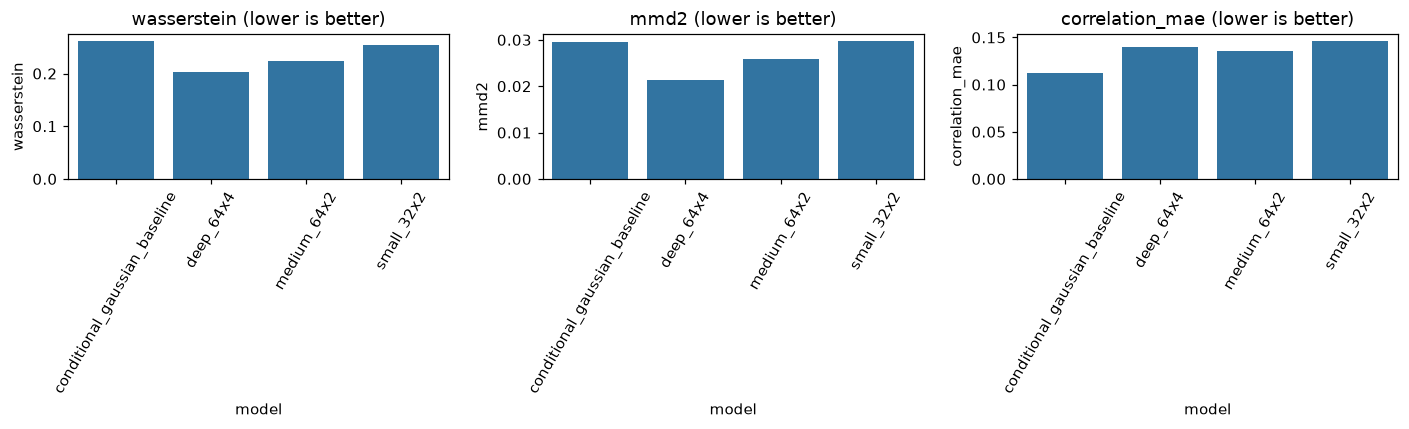

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, metric_name in zip(axes, ['wasserstein', 'mmd2', 'correlation_mae']):
    sns.barplot(data=architecture_summary, x='model', y=metric_name, ax=axis)
    axis.tick_params(axis='x', rotation=60)
    axis.set_title(metric_name + ' (lower is better)')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / '04_architecture_metrics.png', bbox_inches='tight')
plt.show()

## 5. Sample visualizations and feature relationships

A generative model should reproduce **feature relationships**, not merely marginal histograms. Compare generated vs held-out distributions and scatterplots on the original units. We select the architecture with smallest mean MMD² for visualization, but this single held-out split is not a rigorous model-selection procedure; avoid reporting this same holdout as an unbiased final test of the chosen model.

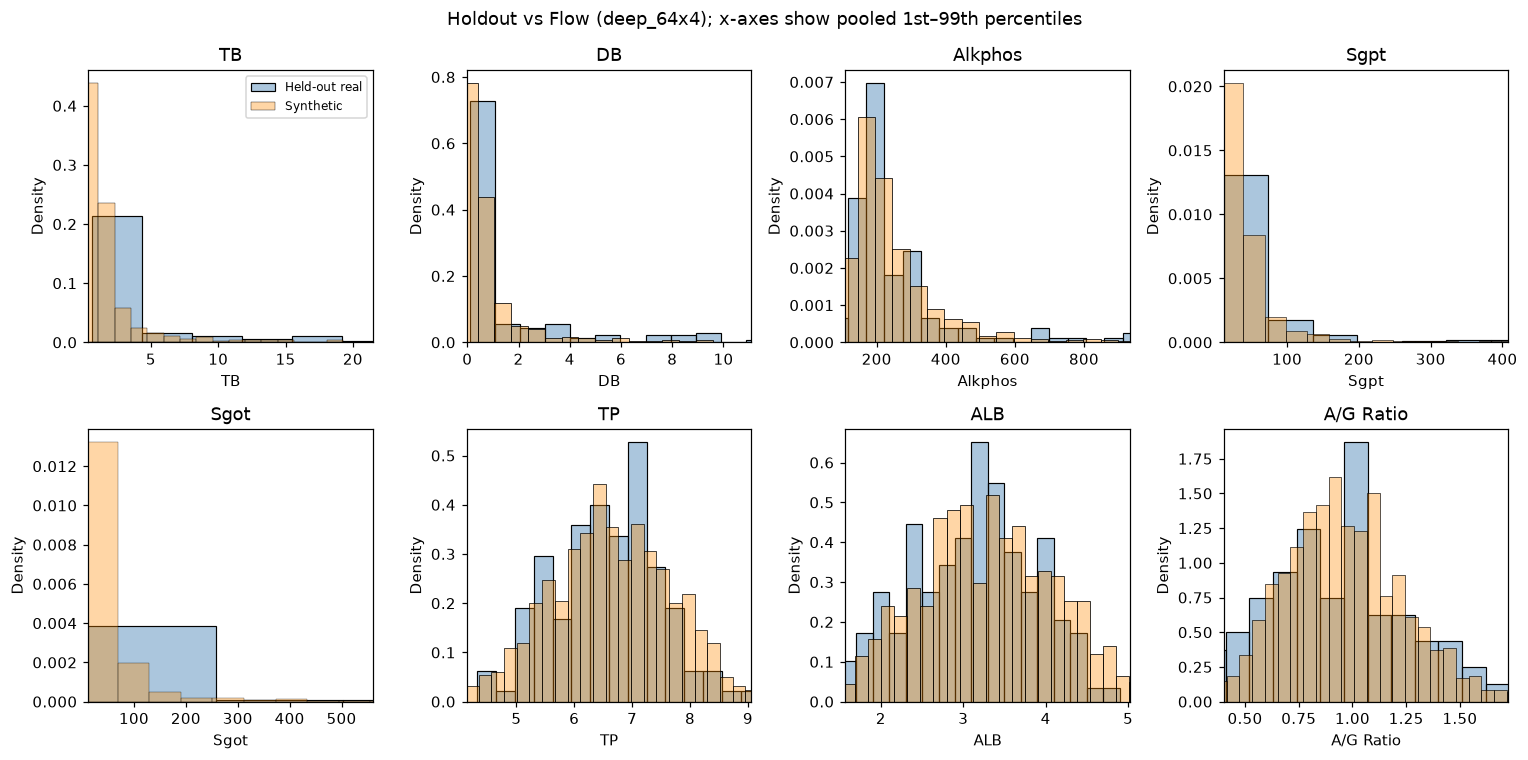

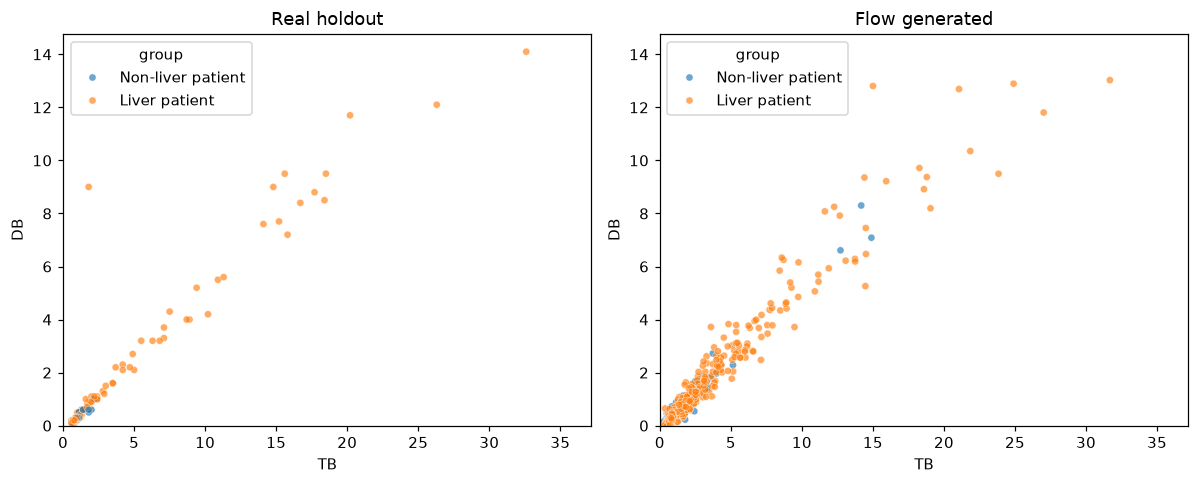

In [9]:
best_model_name = architecture_summary.sort_values('mmd2').iloc[0]['model']
if best_model_name == 'conditional_gaussian_baseline':
    best_model_name = 'medium_64x2'  # Always visualize a flow model here
best_model = trained_models[best_model_name]
visual_labels = np.repeat([0, 1], 500)
visual_generated_scaled = sample_flow(best_model, visual_labels, steps=40, seed=SEED)
visual_generated = as_lab_frame(inverse_lab_transform(visual_generated_scaled))
visual_generated['group'] = np.where(visual_labels == 1, 'Liver patient', 'Non-liver patient')
real_heldout = as_lab_frame(inverse_lab_transform(test_scaled))
real_heldout['group'] = np.where(test_labels == 1, 'Liver patient', 'Non-liver patient')

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for axis, feature_name in zip(axes.flat, FEATURE_COLUMNS):
    sns.histplot(real_heldout[feature_name], ax=axis, stat='density', alpha=0.45,
                 bins=20, color='steelblue', label='Held-out real')
    sns.histplot(visual_generated[feature_name], ax=axis, stat='density', alpha=0.35,
                 bins=30, color='darkorange', label='Synthetic')
    axis.set_title(feature_name)
    # Restrict plotting only (not the underlying evaluation) to reduce extreme outlier effects
    combined = np.r_[real_heldout[feature_name].values, visual_generated[feature_name].values]
    axis.set_xlim(np.quantile(combined, 0.01), np.quantile(combined, 0.99))
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'Holdout vs Flow ({best_model_name}); x-axes show pooled 1st–99th percentiles')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / '05_real_vs_synthetic_histograms.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, frame, name in zip(axes, [real_heldout, visual_generated], ['Real holdout', 'Flow generated']):
    sns.scatterplot(data=frame, x='TB', y='DB', hue='group', alpha=0.65, s=22, ax=axis)
    axis.set_title(name)
    axis.set_xlim(0, max(1, np.quantile(real_heldout['TB'], 0.98) * 1.2))
    axis.set_ylim(0, max(1, np.quantile(real_heldout['DB'], 0.98) * 1.2))
plt.tight_layout()
fig.savefig(OUTPUT_DIR / '06_bilirubin_relationship.png', bbox_inches='tight')
plt.show()

## 6. Sampling steps: speed–quality tradeoff

Sample using the **same initial noise and conditions** for each Euler step count. Compare group-averaged metrics and approximate generation time (hardware-dependent). Fewer steps are faster but can discretize the learned ODE poorly.

,steps,seconds_total,wasserstein,mmd2,correlation_mae,valid_fraction
0,5,0.0053,0.1917,0.0233,0.1396,0.9912
1,10,0.0088,0.1702,0.0164,0.1371,0.9850
2,20,0.0169,0.1647,0.0154,0.1365,0.9800
3,40,0.0317,0.1639,0.0156,0.1362,0.9788
4,80,0.0617,0.1640,0.0158,0.1361,0.9775


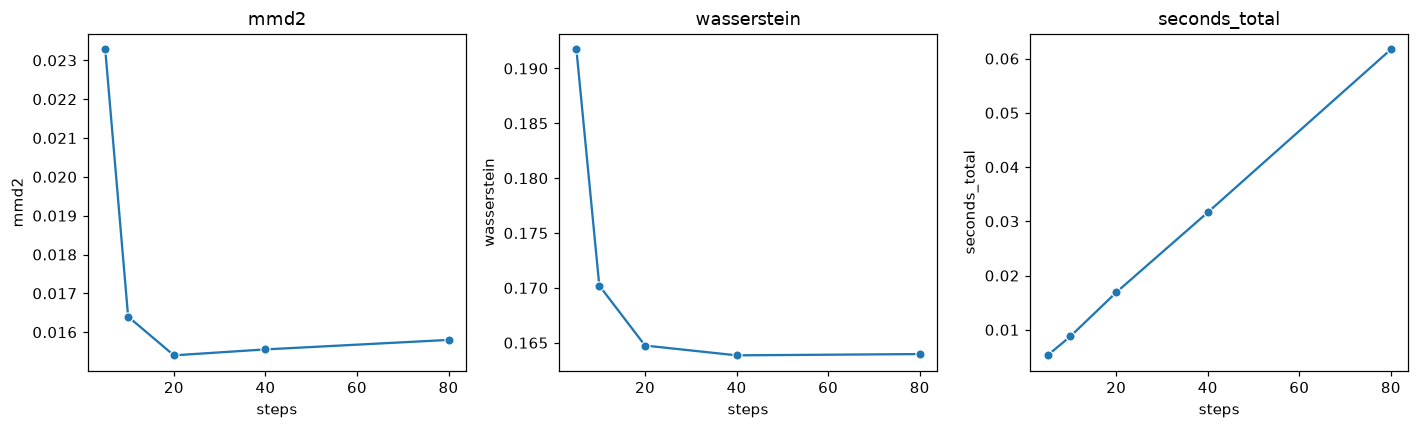

In [10]:
import time
step_metrics = []
step_counts = [5, 10, 20, 40, 80]
step_labels = np.repeat([0, 1], N_SAMPLES_PER_CLASS)
initial_rng = np.random.default_rng(SEED)
shared_initial_noise = initial_rng.standard_normal((len(step_labels), len(FEATURE_COLUMNS))).astype('float32')
for number_of_steps in step_counts:
    start_time = time.perf_counter()
    generated = sample_flow(best_model, step_labels, steps=number_of_steps,
                            initial_noise=shared_initial_noise)
    duration = time.perf_counter() - start_time
    for diagnosis_label in [0, 1]:
        generated_group = generated[step_labels == diagnosis_label]
        heldout_group = test_scaled[test_labels == diagnosis_label]
        score = evaluate_one_group(generated_group, heldout_group)
        step_metrics.append({'steps': number_of_steps,
                             'group': 'Liver patient' if diagnosis_label else 'Non-liver patient',
                             'seconds_total': duration, **score})
step_metrics = pd.DataFrame(step_metrics)
step_metrics.to_csv(OUTPUT_DIR / 'sampling_steps_metrics_by_group.csv', index=False)
step_summary = step_metrics.groupby('steps', as_index=False)[
    ['seconds_total', 'wasserstein', 'mmd2', 'correlation_mae', 'valid_fraction']].mean()
display(step_summary.round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, metric_name in zip(axes, ['mmd2', 'wasserstein', 'seconds_total']):
    sns.lineplot(data=step_summary, x='steps', y=metric_name, marker='o', ax=axis)
    axis.set_title(metric_name)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / '07_sampling_steps_tradeoff.png', bbox_inches='tight')
plt.show()

## 7. Optional: compare training duration

This trains three additional models. To enable, set `RUN_EPOCH_EXPERIMENT = True` in the next code cell. Leave it `False` for faster CPU runs.

In [11]:
RUN_EPOCH_EXPERIMENT = False  # Set True to run the optional training-duration experiment
if RUN_EPOCH_EXPERIMENT:
    duration_results = []
    for epoch_count in [75, 150, 300]:
        duration_model, duration_losses = train_flow(train_scaled, train_labels,
            hidden_dim=64, depth=2, epochs=epoch_count, seed=SEED)
        scores = evaluate_conditional_generator(
            lambda labels, model=duration_model: sample_flow(model, labels, steps=40, seed=SEED))
        duration_results.append({'epochs': epoch_count, 'mmd2': scores['mmd2'].mean(),
                                 'wasserstein': scores['wasserstein'].mean(),
                                 'last_training_loss': duration_losses[-1]})
    duration_results = pd.DataFrame(duration_results)
    duration_results.to_csv(OUTPUT_DIR / 'epoch_experiment.csv', index=False)
    display(duration_results)
else:
    print('Optional epoch experiment skipped. Set RUN_EPOCH_EXPERIMENT = True in this cell to run it.')

Optional epoch experiment skipped. Set RUN_EPOCH_EXPERIMENT = True in this cell to run it.


## 8. Report outline and interpretation checklist

1. **Introduction:** Why generate synthetic liver laboratory measurements? Research question and limitations.
2. **Method:** Conditional flow matching; straight-line interpolation training target; Euler ODE sampling; MLP architecture.
3. **Dataset and preprocessing:** UCI ILPD, class imbalance, training/held-out split, median imputation from train only, log transform, standardization. Model eight lab features conditioned on diagnosis label.
4. **Experimental setup:** Architecture widths/depths, epochs, learning rate, batch size, baseline, same random seed. Discuss why a single split and single seed are limited.
5. **Results:** Loss curves; table with **MMD², mean marginal Wasserstein, correlation MAE, validity**; sampling-step tradeoff; real-vs-generated histograms and scatterplots.
6. **Discussion:** Do larger/deeper models help consistently? Does flow beat conditional Gaussian? What happens with fewer Euler steps? Do generated results violate basic lab constraints? What patterns are artifacts of the small dataset?
7. **Limitations:** 583 records, geographic / selection bias, imbalanced labels, small holdout, noisy metrics, memorization/privacy risks, no clinical validity; no individual record is a diagnosis or validated simulation.

**Further rigor (optional):** Repeat the whole train/test split for 3–5 seeds, report mean ± standard deviation; use a validation split for hyperparameter selection and a separately untouched test split; test nearest-neighbor memorization risks. These are encouraged if time permits.

**Do not state a result until the notebook has been executed.** All plots and metrics are produced on your machine in `outputs/`.